# Imports

In [1]:
import math
import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import pandas as pd
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel
from IPython.display import display
from sklearn.feature_extraction.text import (
    ENGLISH_STOP_WORDS,
    CountVectorizer,
    TfidfVectorizer,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

RANDOM_STATE = 42
CLASS_NAMES = ["FAKE", "TRUE"]


# 1. Статистическая векторизация

Загружаем TRUE- и FAKE-новости с исходными индексами, назначаем целевые метки и создаём стабильные идентификаторы документов вида `КЛАСС:исходный_индекс`. Исходный текст сохраняем без изменений.

In [2]:
true_news_df = pd.read_csv(
    r"..\data\misinformation_n_fake_news\DataSet_Misinfo_TRUE.csv",
    index_col=0,
)
fake_news_df = pd.read_csv(
    r"..\data\misinformation_n_fake_news\DataSet_Misinfo_FAKE.csv",
    index_col=0,
)

true_news_df = true_news_df.copy()
fake_news_df = fake_news_df.copy()
true_news_df["source"] = "TRUE"
fake_news_df["source"] = "FAKE"
true_news_df["target"] = 1
fake_news_df["target"] = 0
true_news_df["original_index"] = true_news_df.index.astype(str)
fake_news_df["original_index"] = fake_news_df.index.astype(str)
true_news_df["document_id"] = "TRUE:" + true_news_df["original_index"]
fake_news_df["document_id"] = "FAKE:" + fake_news_df["original_index"]

raw_corpus_df = pd.concat(
    [true_news_df, fake_news_df],
    ignore_index=True,
)[["document_id", "source", "original_index", "text", "target"]]
print("Строк загружено:", len(raw_corpus_df))
display(raw_corpus_df.head())


Строк загружено: 78617


,document_id,source,original_index,text,target
0,TRUE:0,TRUE,0,The head of a conservative Republican faction ...,1
1,TRUE:1,TRUE,1,Transgender people will be allowed for the fir...,1
2,TRUE:2,TRUE,2,The special counsel investigation of links bet...,1
3,TRUE:3,TRUE,3,Trump campaign adviser George Papadopoulos tol...,1
4,TRUE:4,TRUE,4,President Donald Trump called on the U.S. Post...,1


Проверяем пропуски в обязательных полях и пустые строки. Документы без содержательного текста исключаем с отдельным учётом причин; отсутствие метки или идентификатора считаем ошибкой подготовки данных.

In [3]:
missing_report = raw_corpus_df[["text", "target", "document_id"]].isna().sum()
blank_text_mask = (
    raw_corpus_df["text"].notna()
    & raw_corpus_df["text"].astype(str).str.strip().eq("")
)
blank_id_mask = (
    raw_corpus_df["document_id"].notna()
    & raw_corpus_df["document_id"].astype(str).str.strip().eq("")
)

display(missing_report.rename("Пропусков").to_frame())
print("Пустых текстов:", int(blank_text_mask.sum()))
print("Пустых document_id:", int(blank_id_mask.sum()))

if raw_corpus_df["target"].isna().any():
    raise ValueError("Обнаружены документы без целевой метки.")
if raw_corpus_df["document_id"].isna().any() or blank_id_mask.any():
    raise ValueError("Обнаружены документы без корректного document_id.")
if raw_corpus_df["document_id"].duplicated().any():
    raise ValueError("Стабильные document_id не уникальны внутри исходных файлов.")

missing_text_mask = raw_corpus_df["text"].isna()
prepared_corpus_df = raw_corpus_df.loc[
    ~(missing_text_mask | blank_text_mask)
].copy()
prepared_corpus_df["text"] = prepared_corpus_df["text"].astype(str)

preparation_report_df = pd.DataFrame(
    {
        "Причина": [
            "Строк до обработки",
            "Исключено: отсутствует text",
            "Исключено: text пуст или состоит из пробелов",
            "Строк после проверки обязательных полей",
        ],
        "Количество": [
            len(raw_corpus_df),
            int(missing_text_mask.sum()),
            int(blank_text_mask.sum()),
            len(prepared_corpus_df),
        ],
    }
)
display(preparation_report_df)


,Пропусков
text,29
target,0
document_id,0


Пустых текстов: 0
Пустых document_id: 0


,Причина,Количество
0,Строк до обработки,78617
1,Исключено: отсутствует text,29
2,Исключено: text пуст или состоит из пробелов,0
3,Строк после проверки обязательных полей,78588


До разбиения канонизируем только внешние пробелы, находим точные повторы и конфликты меток. Конфликтные тексты полностью исключаем, а среди однозначных повторов детерминированно сохраняем первую строку и её `document_id`.

In [4]:
prepared_corpus_df["canonical_text"] = prepared_corpus_df["text"].str.strip()
duplicate_rows_count = int(
    prepared_corpus_df["canonical_text"].duplicated(keep=False).sum()
)
duplicate_excess_count = int(
    prepared_corpus_df["canonical_text"].duplicated(keep="first").sum()
)
label_counts_by_text = prepared_corpus_df.groupby("canonical_text")[
    "target"
].nunique()
conflicting_texts = set(label_counts_by_text[label_counts_by_text > 1].index)
conflict_rows_df = prepared_corpus_df[
    prepared_corpus_df["canonical_text"].isin(conflicting_texts)
].sort_values(["canonical_text", "document_id"])

print("Строк, входящих в группы точных повторов:", duplicate_rows_count)
print("Лишних повторных строк:", duplicate_excess_count)
print("Текстов с конфликтующими метками:", len(conflicting_texts))
if not conflict_rows_df.empty:
    display(
        conflict_rows_df[
            ["document_id", "target", "text"]
        ].assign(text=lambda frame: frame["text"].str.slice(0, 300))
    )

corpus_df = (
    prepared_corpus_df[
        ~prepared_corpus_df["canonical_text"].isin(conflicting_texts)
    ]
    .drop_duplicates(subset="canonical_text", keep="first")
    .reset_index(drop=True)
)
assert corpus_df["document_id"].is_unique
assert not corpus_df["canonical_text"].duplicated().any()
print("Документов после разрешения повторов и конфликтов:", len(corpus_df))


Строк, входящих в группы точных повторов: 18428
Лишних повторных строк: 9984
Текстов с конфликтующими метками: 0
Документов после разрешения повторов и конфликтов: 68604


Определяем единый детерминированный конвейер очистки в порядке из лабораторной работы №1. Значимый шум заменяется специальными маркерами; обычные токены приводятся к нижнему регистру. В режиме `query` отключены только правила дейтлайна и издателя.

In [5]:
PUBLISHERS = [
    "Reuters", "Associated Press", "AP", "AFP", "Agence France-Presse",
    "New York Times", "NYTimes", "Washington Post", "Wall Street Journal",
    "WSJ", "CNN", "BBC", "Fox News", "NBC News", "CBS News",
    "ABC News", "The Guardian", "Bloomberg", "Politico", "USA Today",
    "HuffPost", "Xinhua", "Sputnik", "RT", "Russia Today", "TASS",
    "Breitbart", "Redflag Newsdesk", "Truth Broadcast Network",
    "EUvsDisinfo",
]
PUBLISHER_REGEXES = [
    r"\b" + re.escape(name).replace(r"\ ", r"\s+") + r"\b"
    for name in sorted(PUBLISHERS, key=len, reverse=True)
]
PUBLISHER_COMBINED_REGEX = r"(?:" + "|".join(PUBLISHER_REGEXES) + r")"
DATELINE_COMBINED_REGEX = (
    rf"(?i)^\s*(?:"
    rf"[A-Z][A-Z\s.,'-]{{2,100}}\s*"
    rf"\(\s*{PUBLISHER_COMBINED_REGEX}\s*\)"
    rf"|[A-Z][A-Za-z\s.,'-]{{2,100}},?\s+"
    rf"[A-Za-z]{{3,9}}\s+\d{{1,2}}\s*"
    rf"\(\s*{PUBLISHER_COMBINED_REGEX}\s*\)"
    rf"|[A-Z][A-Za-z\s.,'-]{{2,100}},?\s*"
    rf"{PUBLISHER_COMBINED_REGEX}"
    rf"|By\s+{PUBLISHER_COMBINED_REGEX}"
    rf"|(?:Source|Copyright)\s*:?\s*{PUBLISHER_COMBINED_REGEX}"
    rf")\s*[-—–:,]?\s*"
)
PUBLISHER_CONTEXT_REGEX = (
    rf"(?i)(?:"
    rf"\(\s*{PUBLISHER_COMBINED_REGEX}\s*\)"
    rf"|\b(?:Source|Copyright)\s*:?\s*{PUBLISHER_COMBINED_REGEX}"
    rf"|\bBy\s+{PUBLISHER_COMBINED_REGEX}"
    rf")"
)
NOISE_RULES = [
    ("Новостные дейтлайны", DATELINE_COMBINED_REGEX, "[DATELINE]"),
    ("Указание издателя", PUBLISHER_CONTEXT_REGEX, "[PUBLISHER]"),
    ("HTML-теги", r"<[^>]+>", "[HTML]"),
    ("HTML-сущности", r"&(?:[a-zA-Z]+|#[0-9]+|#x[0-9a-fA-F]+);", "[HTML_ENTITY]"),
    ("Email-адреса", r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b", "[EMAIL]"),
    ("URL-адреса", r"(?:https?://|www\.)\S+|(?<![\w@])(?:[A-Za-z0-9-]+\.)+[a-z]{2,63}(?:/[^\s]*)?", "[URL]"),
    ("Упоминания", r"(?<![\w.%+-])@[A-Za-z0-9_]+", "[MENTION]"),
    ("Хештеги", r"(?<!\w)#[A-Za-z0-9_]+", "[TAG]"),
    ("Числа", r"\d+(?:[.,]\d+)?", "[NUM]"),
    ("Повторная пунктуация", r"[!?.,]{2,}", "[PUNCT]"),
    ("Лишние пробелы", r"\s{2,}", " "),
    ("Нестандартные символы", r"[^\w\s.,!?;:'\"()\[\]{}%$€£-]", "[SYM]"),
]
SPECIAL_MARKERS = {
    "[DATELINE]", "[PUBLISHER]", "[HTML]", "[HTML_ENTITY]", "[EMAIL]",
    "[URL]", "[MENTION]", "[TAG]", "[NUM]", "[PUNCT]", "[SYM]",
}
TOKEN_PATTERN = re.compile(r"\[[A-Z_]+\]|[A-Za-z]+(?:'[A-Za-z]+)?")


def clean_text(text: str, mode: str = "document") -> str:
    """
    Очищает текст единым детерминированным набором правил.

    Parameters:
        text (str): Исходный текст.
        mode (str): Режим document или query. По умолчанию: document.

    Returns:
        str: Очищенный текст с сохранёнными специальными маркерами.

    Fallbacks:
        Для пропуска возвращает пустую строку; неизвестный режим вызывает ошибку.
    """
    if mode not in {"document", "query"}:
        raise ValueError("Режим должен быть равен 'document' или 'query'.")
    if pd.isna(text):
        return ""

    cleaned = str(text)
    for rule_index, (_, pattern, replacement) in enumerate(NOISE_RULES):
        if mode == "query" and rule_index < 2:
            continue
        cleaned = re.sub(pattern, replacement + " ", cleaned)

    cleaned = re.sub(r"\s+", " ", cleaned).strip()
    segments = re.split(r"(\[[A-Z_]+\])", cleaned)
    return "".join(
        segment if segment in SPECIAL_MARKERS else segment.lower()
        for segment in segments
    )


Проверяем каждое правило на компактном примере, сохранность маркеров, lowercase обычных слов и отсутствие технических токенов языковой модели из лабораторной работы №1.

In [6]:
cleaner_example = (
    "WASHINGTON (Reuters) - Source: BBC <b>Breaking</b> &amp; "
    "mail news@example.com, visit https://example.com, @editor #Update "
    "12.5 times!!! ☃"
)
cleaner_result = clean_text(cleaner_example)
query_mode_result = clean_text("By Reuters Economy Update", mode="query")

for marker in SPECIAL_MARKERS:
    assert marker in cleaner_result, f"Не найден маркер {marker}"
assert "breaking" in cleaner_result and "Breaking" not in cleaner_result
assert all(token not in cleaner_result for token in ("<s>", "</s>", "[UNK]"))
assert "reuters" in query_mode_result and "[DATELINE]" not in query_mode_result

print("Исходный пример:", cleaner_example)
print("После очистки:", cleaner_result)
print("Запрос в режиме query:", query_mode_result)


Исходный пример: WASHINGTON (Reuters) - Source: BBC <b>Breaking</b> &amp; mail news@example.com, visit https://example.com, @editor #Update 12.5 times!!! ☃
После очистки: [DATELINE] [PUBLISHER] [HTML] breaking[HTML] [HTML_ENTITY] mail [EMAIL] , visit [URL] [MENTION] [TAG] [NUM] times[PUNCT] [SYM]
Запрос в режиме query: by reuters economy update


Перед разделением корпуса применяем `clean_text` ко всем документам, диагностируем коллизии нормализации и оставляем только первый документ для каждого уникального `clean_text`. Затем делим очищенный от коллизий корпус на Train/Test со стратификацией и проверяем отсутствие пересечений и повторов.

In [7]:
corpus_df["clean_text"] = corpus_df["text"].map(clean_text)
normalized_collisions_df = (
    corpus_df.groupby("clean_text")
    .agg(
        documents=("document_id", "size"),
        source_texts=("canonical_text", "nunique"),
        document_ids=("document_id", lambda values: list(values)[:5]),
    )
    .query("source_texts > 1")
    .sort_values("documents", ascending=False)
)
collision_rows_count = int(
    corpus_df.duplicated(subset="clean_text", keep="first").sum()
)
corpus_df = (
    corpus_df.drop_duplicates(subset="clean_text", keep="first")
    .reset_index(drop=True)
)

assert corpus_df["document_id"].is_unique
assert corpus_df["canonical_text"].is_unique
assert corpus_df["clean_text"].is_unique

train_df, test_df = train_test_split(
    corpus_df,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=corpus_df["target"],
)
train_df = train_df.drop_duplicates(
    subset="clean_text", keep="first"
).copy()
test_df = (
    test_df[~test_df["clean_text"].isin(train_df["clean_text"])]
    .drop_duplicates(subset="clean_text", keep="first")
    .copy()
)

assert set(train_df["document_id"]).isdisjoint(test_df["document_id"])
assert set(train_df["canonical_text"]).isdisjoint(test_df["canonical_text"])
assert set(train_df["clean_text"]).isdisjoint(test_df["clean_text"])
assert train_df["document_id"].is_unique and test_df["document_id"].is_unique

corpus_df = pd.concat([train_df, test_df]).sort_index()
print("Групп коллизий нормализации:", len(normalized_collisions_df))
print("Удалено документов из групп коллизий:", collision_rows_count)
print("Train/Test после фильтрации:", train_df.shape, test_df.shape)
display(normalized_collisions_df.head(10))


Групп коллизий нормализации: 39
Удалено документов из групп коллизий: 110
Train/Test после фильтрации: (54795, 7) (13699, 7)


,documents,source_texts,document_ids
clean_text,,,
[URL],53,53,"[FAKE:9358, FAKE:11251, FAKE:11286, FAKE:11288..."
"notify me of follow-up comments by email. notify me of new posts by email. security question: what is [NUM] [SYM] [NUM] ? please leave these two fields as-is: important! to be able to proceed, you need to solve the following simple math (so we know that you are a human) :-) doom and bloom",10,10,"[FAKE:25893, FAKE:26310, FAKE:26895, FAKE:2823..."
"x dear reader! [URL] isn[SYM] t just a website. we are the voice of the historic american nation . our goal is nothing less than to develop a full spectrum media network to speak up for our people during this difficult time for our country. part of that means building institutions which are offline and in the real world. there[SYM] s something about a paper journal that suggests permanence, which inclines people to take it more seriously. and because the news cycle is so fast, some of the most important, substantial, and potentially influential writings fall through the cracks and don[SYM] t get the attention they deserve. for that reason, we[SYM] re proud to announce the creation of vdare quarterly, a print journal featuring the best material from our webzine. this will replace our yearly anthologies and ensure that the information and analysis you really don't want to miss will get in front of you as quickly as possible. however, we need your help. for us to unveil this exciting new product we need [NUM] magazines ordered to cover the print expenses. fill out the form below to instantly receive a digital copy of vdare quarterly, and when we have the number of necessary subscribers it will go to print and your exclusive paper copy will ship directly to you! depending on the package you choose, you will receive multiple paper copies (provided enough readers support the community effort). we encourage you to pass these around [SYM] they serve as an excellent gift for friends and family, while at the same time helping to build our community. vdare quarterly is aesthetically pleasing as well as ideologically powerful. but this isn[SYM] t just a service we are providing. vdare quarterly is a tangible manifestation of your investment in us, and in our country. a subscription is one of the most effective ways you can help us build our media network, expand our influence, and build the kind of movement we will need to take back our country and ensure our children have a recognizable america. we count on your support! yours sincerely, peter brimelow, editor of [URL] vdare quarterly countdown: [NUM] already ordered, [NUM] still to go",6,6,"[FAKE:24985, FAKE:27981, FAKE:28754, FAKE:2924..."
"posted: nov [NUM] th, [NUM] by guest click for more article by guest [PUNCT] more stories about: ticker",4,4,"[FAKE:24598, FAKE:26276, FAKE:26780, FAKE:31010]"
"[NUM] mins ago [NUM] views [NUM] comments [NUM] likes drone footage shows the devastation caused by twin earthquakes that rocked borgo sant'antonio, near visso, which left buildings reduced to rubble or partially collapsed. central italy was struck twice in quick succession the previous day, with the first tremor hitting it at around [NUM] :[NUM] local time ([NUM] :[NUM] gmt). the quake measured [NUM] on the richter scale and could be felt as far as rome some [NUM] km ([NUM] miles). shortly after a second quake of [NUM] -magnitude, struck at around [NUM] :[NUM] local time ([NUM] :[NUM] gmt). buildings were shaking, some parts even caving in, and residents fled into the street to save themselves. several dozen people have been treated across the region for light injuries, while four are said to have been seriously hurt. courtesy: rt's ruptly video agency, no re-upload, no reuse - for licensing, please, contact [URL] subscribe like leave a reply login with your social id your email address will not be published. name",4,4,"[FAKE:24119, FAKE:30022, FAKE:31008, FAKE:33538]"
"[NUM] mins ago [NUM] views [NUM] comments [NUM] likes it's fair 

Обучаем независимые Bag of Words и TF-IDF vectorizer только на Train (`fit_transform`), а Test преобразуем только методом `transform`. Специальные маркеры распознаются как единые признаки; матрицы остаются разреженными.

In [9]:
VECTORIZER_TOKEN_PATTERN = r"(?u)\[[A-Z_]+\]|\b[a-zA-Z]+(?:'[a-zA-Z]+)?\b"
bow_vectorizer = CountVectorizer(
    token_pattern=VECTORIZER_TOKEN_PATTERN,
    lowercase=False,
)
tfidf_vectorizer = TfidfVectorizer(
    token_pattern=VECTORIZER_TOKEN_PATTERN,
    lowercase=False,
)

x_train_bow = bow_vectorizer.fit_transform(train_df["clean_text"])
x_test_bow = bow_vectorizer.transform(test_df["clean_text"])
x_train_tfidf = tfidf_vectorizer.fit_transform(train_df["clean_text"])
x_test_tfidf = tfidf_vectorizer.transform(test_df["clean_text"])

expected_marker_tokens = sorted(SPECIAL_MARKERS)
assert bow_vectorizer.build_analyzer()(" ".join(expected_marker_tokens)) == expected_marker_tokens
assert tfidf_vectorizer.build_analyzer()(" ".join(expected_marker_tokens)) == expected_marker_tokens
train_markers = {
    token
    for text in train_df["clean_text"]
    for token in TOKEN_PATTERN.findall(text)
    if token in SPECIAL_MARKERS
}
assert train_markers.issubset(bow_vectorizer.vocabulary_)
assert train_markers.issubset(tfidf_vectorizer.vocabulary_)
vectorization_report_df = pd.DataFrame(
    [
        (
            "Bag of Words", x_train_bow.shape, x_test_bow.shape,
            x_train_bow.nnz, x_test_bow.nnz,
            len(bow_vectorizer.vocabulary_),
        ),
        (
            "TF-IDF", x_train_tfidf.shape, x_test_tfidf.shape,
            x_train_tfidf.nnz, x_test_tfidf.nnz,
            len(tfidf_vectorizer.vocabulary_),
        ),
    ],
    columns=[
        "Представление", "Форма Train", "Форма Test", "NNZ Train",
        "NNZ Test", "Размер словаря",
    ],
)
display(vectorization_report_df)


,Представление,Форма Train,Форма Test,NNZ Train,NNZ Test,Размер словаря
0,Bag of Words,"(54795, 161032)","(13699, 161032)",12646427,3112085,161032
1,TF-IDF,"(54795, 161032)","(13699, 161032)",12646427,3112085,161032


### Вывод

После исключения 29 пропусков и 9 984 лишних точных повторов осталось 68 604 документа; конфликтов меток среди одинаковых текстов не найдено. После очистки обнаружено 39 групп коллизий и удалено ещё 110 документов, поэтому итоговый корпус содержит 68 494 документа. Разные исходные тексты могут сворачиваться в одинаковое представление главным образом из-за замены URL, чисел и другого шума маркерами, поэтому исходный `text` и стабильный `document_id` сохранены для диагностики.

Оба представления имеют одинаковую форму: Train — `(54 795, 161 032)`, Test — `(13 699, 161 032)`, словарь содержит 161 032 признака. Число ненулевых элементов также совпадает: 12 646 427 для Train и 3 112 085 для Test, поскольку оба метода используют одну и ту же униграммную токенизацию. Различаются значения признаков: BoW хранит абсолютные частоты, а TF-IDF уменьшает вес частых во всём Train терминов и усиливает более специфичные слова. Словарь и веса рассчитаны только по Train.

# 2. Обучение классификаторов

Показываем распределение классов Train и обучаем на TF-IDF наивный байесовский классификатор и логистическую регрессию с балансировкой классов. Параметры фиксируются до оценки на Test.

In [10]:
class_distribution_df = (
    train_df["target"]
    .value_counts()
    .sort_index()
    .rename(index={0: "FAKE", 1: "TRUE"})
    .rename("Документов")
    .to_frame()
)
class_distribution_df["Доля"] = (
    class_distribution_df["Документов"] / len(train_df)
)
display(class_distribution_df)

models = {
    "MultinomialNB": MultinomialNB(),
    "LogisticRegression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
}
for model in models.values():
    model.fit(x_train_tfidf, train_df["target"])

model_parameters_df = pd.DataFrame(
    [
        ("MultinomialNB", 1.0, None, None),
        ("LogisticRegression", None, "balanced", 1000),
    ],
    columns=["Модель", "alpha", "class_weight", "max_iter"],
)
display(model_parameters_df)


,Документов,Доля
target,,
FAKE,27175,0.495939
TRUE,27620,0.504061


,Модель,alpha,class_weight,max_iter
0,MultinomialNB,1.0,NaN,NaN
1,LogisticRegression,NaN,balanced,1000.0


# 3. Оценка качества классификации

Получаем предсказания на Test, рассчитываем macro-метрики и вспомогательную Accuracy. Лучшую модель выбираем исключительно по Macro F1.

In [11]:
predictions = {
    model_name: model.predict(x_test_tfidf)
    for model_name, model in models.items()
}
metrics_rows = []
for model_name, predicted_target in predictions.items():
    precision, recall, f1, _ = precision_recall_fscore_support(
        test_df["target"],
        predicted_target,
        average="macro",
        zero_division=0,
    )
    metrics_rows.append(
        (
            model_name,
            precision,
            recall,
            f1,
            accuracy_score(test_df["target"], predicted_target),
        )
    )

classification_metrics_df = pd.DataFrame(
    metrics_rows,
    columns=[
        "Модель", "Macro Precision", "Macro Recall", "Macro F1", "Accuracy",
    ],
).sort_values(["Macro F1", "Модель"], ascending=[False, True])
best_model_name = classification_metrics_df.iloc[0]["Модель"]
print("Лучшая модель по Macro F1:", best_model_name)
display(classification_metrics_df)


Лучшая модель по Macro F1: LogisticRegression


,Модель,Macro Precision,Macro Recall,Macro F1,Accuracy
1,LogisticRegression,0.950502,0.950530,0.950506,0.950507
0,MultinomialNB,0.872239,0.871022,0.871092,0.871231


Строим матрицы ошибок обеих моделей с единым порядком классов `FAKE`, `TRUE`.

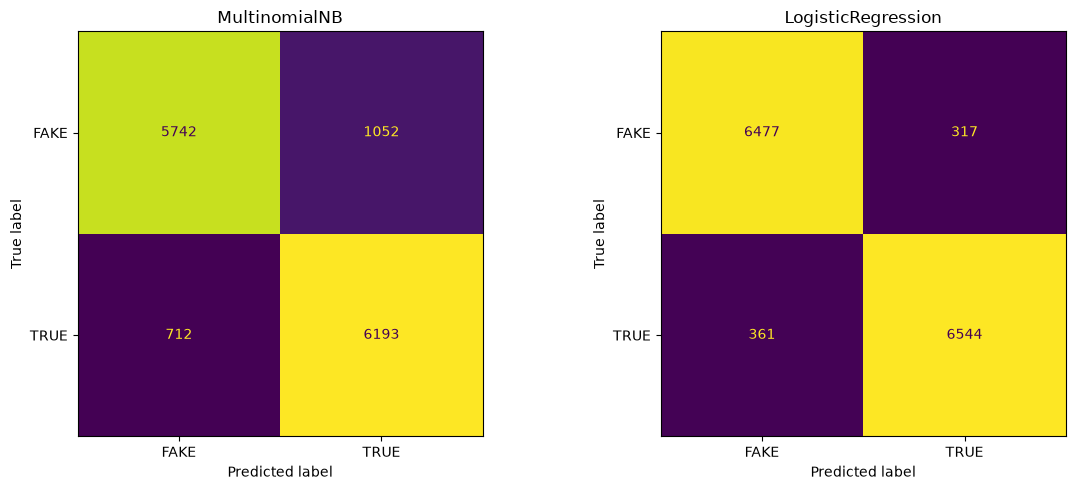

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for axis, (model_name, predicted_target) in zip(axes, predictions.items()):
    matrix = confusion_matrix(
        test_df["target"],
        predicted_target,
        labels=[0, 1],
    )
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=CLASS_NAMES,
    ).plot(ax=axis, colorbar=False)
    axis.set_title(model_name)
plt.tight_layout()
plt.show()


Для лучшей модели детерминированно выбираем пять ошибок по `document_id` и показываем исходный, а не очищенный текст.

In [13]:
error_analysis_df = test_df[
    ["document_id", "text", "target"]
].copy()
error_analysis_df["predicted_target"] = predictions[best_model_name]
error_analysis_df = (
    error_analysis_df[
        error_analysis_df["target"] != error_analysis_df["predicted_target"]
    ]
    .sort_values("document_id")
    .head(5)
)
error_analysis_df["Истинный класс"] = error_analysis_df["target"].map(
    {0: "FAKE", 1: "TRUE"}
)
error_analysis_df["Предсказанный класс"] = error_analysis_df[
    "predicted_target"
].map({0: "FAKE", 1: "TRUE"})
error_analysis_df["Фрагмент исходного текста"] = (
    error_analysis_df["text"].str.replace(r"\s+", " ", regex=True).str.slice(0, 500)
)
display(
    error_analysis_df[
        [
            "document_id", "Истинный класс", "Предсказанный класс",
            "Фрагмент исходного текста",
        ]
    ]
)


,document_id,Истинный класс,Предсказанный класс,Фрагмент исходного текста
44692,FAKE:10170,FAKE,TRUE,Arrogant and smug is what we d call McConnell ...
44702,FAKE:10180,FAKE,TRUE,OKLAHOMA CITY The Oklahoma Supreme Court ruled...
44808,FAKE:10286,FAKE,TRUE,Establishment Republican Reince Priebus is gon...
44813,FAKE:10291,FAKE,TRUE,It s clear that some Republicans never wanted ...
44816,FAKE:10294,FAKE,TRUE,"Yes, this will happen! America needs a wall at..."


### Анализ результатов и ошибок

Логистическая регрессия стала лучшей по Macro F1: `0,9505` против `0,8711` у MultinomialNB; её Macro Precision и Macro Recall также равны примерно `0,9505`. Accuracy почти совпала с macro-метриками из-за практически равного распределения классов в Train (`49,59%` FAKE и `50,41%` TRUE), однако сама по себе она не показывает, какой класс распознаётся хуже, и при изменении баланса может скрыть слабое качество меньшего класса. Поэтому основной критерий — Macro F1, дающий классам равный вес.

Все пять детерминированно выбранных ошибок — FAKE, предсказанные как TRUE. Документы `FAKE:10170`, `FAKE:10286`, `FAKE:10291` и `FAKE:10294` содержат длинные цитаты политиков и фрагменты новостных сообщений с институциональной лексикой; `FAKE:10180` почти полностью написан в нейтральном стиле локальной новости. Их редакционные оценки либо сосредоточены в коротком вступлении/заключении, либо отсутствуют, а основная часть похожа на профессиональную хронику. TF-IDF-модель улавливает лексический стиль, но не проверяет источник и достоверность утверждений, поэтому перепечатанный фактический материал внутри FAKE-корпуса систематически сближает такие тексты с TRUE.

# 4. Построение инвертированного индекса

Для поиска используем весь подготовленный дедуплицированный корпус. Документы очищаются в режиме `document`, затем из поискового представления исключаются специальные маркеры, английские стоп-слова и обычные токены короче трёх символов.

In [14]:
def tokenize_for_search(text: str, mode: str = "document") -> list[str]:
    """
    Формирует содержательные поисковые токены документа или запроса.

    Parameters:
        text (str): Исходный документ или пользовательский запрос.
        mode (str): Режим document или query. По умолчанию: document.

    Returns:
        list[str]: Токены без стоп-слов, коротких слов и шумовых маркеров.

    Fallbacks:
        Для пустого или бессодержательного текста возвращает пустой список.
    """
    cleaned = clean_text(text, mode=mode)
    return [
        token
        for token in TOKEN_PATTERN.findall(cleaned)
        if token not in SPECIAL_MARKERS
        and len(token) >= 3
        and token not in ENGLISH_STOP_WORDS
    ]


search_tokens_by_id = {
    row.document_id: tokenize_for_search(row.text, mode="document")
    for row in corpus_df[["document_id", "text"]].itertuples(index=False)
}
empty_search_documents = [
    document_id
    for document_id, tokens in search_tokens_by_id.items()
    if not tokens
]
clean_token_counts = Counter(
    token
    for text in corpus_df["clean_text"]
    for token in TOKEN_PATTERN.findall(text)
)
marker_count = sum(clean_token_counts[marker] for marker in SPECIAL_MARKERS)
total_clean_tokens = sum(clean_token_counts.values())
print("Пустых поисковых документов:", len(empty_search_documents))
print("Доля специальных маркеров до фильтрации:", marker_count / total_clean_tokens)


Пустых поисковых документов: 66
Доля специальных маркеров до фильтрации: 0.043247121708276895


За один проход строим posting lists, частоты терминов, длины документов и среднюю длину непустого индексируемого документа. Пустые документы остаются в общем корпусе, но не создают postings.

In [15]:
inverted_index = defaultdict(set)
document_term_frequencies = {}
document_lengths = {}
corpus_term_counts = Counter()

for document_id, tokens in search_tokens_by_id.items():
    term_frequencies = Counter(tokens)
    document_term_frequencies[document_id] = term_frequencies
    document_lengths[document_id] = len(tokens)
    corpus_term_counts.update(term_frequencies)
    for term in term_frequencies:
        inverted_index[term].add(document_id)

nonempty_lengths = [length for length in document_lengths.values() if length > 0]
average_document_length = (
    sum(nonempty_lengths) / len(nonempty_lengths)
    if nonempty_lengths
    else 0.0
)
indexed_document_ids = set().union(*inverted_index.values()) if inverted_index else set()
assert indexed_document_ids.issubset(set(corpus_df["document_id"]))
assert all(
    len(postings) == len(set(postings))
    for postings in inverted_index.values()
)
assert not (set(inverted_index) & SPECIAL_MARKERS)

print("Размер словаря индекса:", len(inverted_index))
print("Средняя длина непустого документа:", average_document_length)
display(
    pd.DataFrame(
        corpus_term_counts.most_common(20),
        columns=["Термин", "Частота"],
    )
)
display(
    pd.DataFrame(
        [
            (term, len(inverted_index[term]), sorted(inverted_index[term])[:5])
            for term in sorted(inverted_index)[:10]
        ],
        columns=["Термин", "Документов", "Примеры document_id"],
    )
)


Размер словаря индекса: 182415
Средняя длина непустого документа: 244.49045712281523


,Термин,Частота
0,said,203772
1,trump,184744
2,president,77217
3,people,77142
4,new,59887
5,clinton,58947
6,state,54129
7,like,48484
8,just,46617
9,states,43512


,Термин,Документов,Примеры document_id
0,a'ali,1,[FAKE:28891]
1,a's,1,[FAKE:9576]
2,aaa,27,"[FAKE:13585, FAKE:13641, FAKE:2129, FAKE:24774..."
3,aaaaaaaand,1,[FAKE:2296]
4,aaaaackkk,1,[FAKE:3377]
5,aaaaah,1,[TRUE:25785]
6,aaaaggg,1,[FAKE:27967]
7,aaaahhh,1,[TRUE:27214]
8,aaaahhhh,1,[FAKE:14135]
9,aaaand,1,[FAKE:1201]


# 5. Реализация поискового движка BM25

Нормализуем запрос в режиме `query`, объединяем кандидатов через posting lists и рассчитываем положительный Okapi BM25 IDF. Результаты сортируются по убыванию score и затем по `document_id`.

In [16]:
def bm25_search(
    query: str,
    top_k: int = 5,
    k1: float = 1.5,
    b: float = 0.75,
) -> list[dict[str, object]]:
    """
    Ранжирует документы по положительной формуле Okapi BM25.

    Parameters:
        query (str): Произвольный пользовательский запрос.
        top_k (int): Максимальное число результатов. По умолчанию: 5.
        k1 (float): Насыщение частоты термина. По умолчанию: 1.5.
        b (float): Нормализация длины документа. По умолчанию: 0.75.

    Returns:
        list[dict[str, object]]: Ранжированные document_id и BM25 score.

    Fallbacks:
        Для пустого, бессодержательного или неизвестного запроса возвращает пустой список.
    """
    if top_k <= 0 or average_document_length == 0:
        return []
    query_terms = tokenize_for_search(query, mode="query")
    known_query_terms = [term for term in query_terms if term in inverted_index]
    if not known_query_terms:
        return []

    query_term_counts = Counter(known_query_terms)
    candidates = set().union(
        *(inverted_index[term] for term in query_term_counts)
    )
    document_count = len(corpus_df)
    ranked_results = []
    for document_id in candidates:
        score = 0.0
        document_length = document_lengths[document_id]
        for term, query_frequency in query_term_counts.items():
            term_frequency = document_term_frequencies[document_id][term]
            if term_frequency == 0:
                continue
            document_frequency = len(inverted_index[term])
            inverse_document_frequency = math.log(
                1
                + (document_count - document_frequency + 0.5)
                / (document_frequency + 0.5)
            )
            denominator = term_frequency + k1 * (
                1 - b + b * document_length / average_document_length
            )
            score += (
                query_frequency
                * inverse_document_frequency
                * term_frequency
                * (k1 + 1)
                / denominator
            )
        if score > 0 and math.isfinite(score):
            ranked_results.append(
                {"document_id": document_id, "score": score}
            )

    return sorted(
        ranked_results,
        key=lambda result: (-result["score"], result["document_id"]),
    )[:top_k]


assert bm25_search("") == []
assert bm25_search("the and of") == []
assert bm25_search("qwertyuiopasdfgh") == []


Проверяем поиск на трёх содержательно разных англоязычных запросах и показываем исходные тексты найденных документов.

In [17]:
search_queries = [
    "presidential election campaign",
    "climate change international agreement",
    "healthcare insurance reform",
]
corpus_lookup_df = corpus_df.set_index("document_id")
for query in search_queries:
    result_rows = []
    for rank, result in enumerate(bm25_search(query, top_k=5), start=1):
        document = corpus_lookup_df.loc[result["document_id"]]
        result_rows.append(
            (
                rank,
                result["score"],
                result["document_id"],
                CLASS_NAMES[int(document["target"])],
                re.sub(r"\s+", " ", document["text"])[:500],
            )
        )
    print(f"Запрос: {query}")
    display(
        pd.DataFrame(
            result_rows,
            columns=[
                "Ранг", "BM25 score", "document_id", "Класс",
                "Фрагмент исходного текста",
            ],
        )
    )


Запрос: presidential election campaign


,Ранг,BM25 score,document_id,Класс,Фрагмент исходного текста
0,1,9.523628,FAKE:28670,FAKE,2016 US Presidential Election ( 45 ) 0 14 0 0 ...
1,2,9.516435,FAKE:31815,FAKE,Mayhem Awaits As Crooked Hillary Clinton Is No...
2,3,9.442322,FAKE:33119,FAKE,The Washington Post reported : Donald Trump ra...
3,4,9.337764,TRUE:8564,TRUE,U.S. Democratic presidential candidate Hillary...
4,5,9.325536,FAKE:14411,FAKE,Hey Bernie The first step in fighting corrupti...


Запрос: climate change international agreement


,Ранг,BM25 score,document_id,Класс,Фрагмент исходного текста
0,1,21.144609,FAKE:24626,FAKE,"November 4, 2016 Landmark Paris Climate Agreem..."
1,2,20.582106,TRUE:7328,TRUE,The election of climate change skeptic Donald ...
2,3,19.941763,TRUE:7363,TRUE,U.S. President-elect Donald Trump could use le...
3,4,19.882700,TRUE:4528,TRUE,The United States should continue to be “engag...
4,5,19.559150,TRUE:3449,TRUE,Japan said on Friday the decision by the Unite...


Запрос: healthcare insurance reform


,Ранг,BM25 score,document_id,Класс,Фрагмент исходного текста
0,1,19.573651,TRUE:4595,TRUE,A looming push to overhaul the U.S. tax code c...
1,2,19.521574,TRUE:2396,TRUE,U.S. Senator Rand Paul said he spoke to Presid...
2,3,19.070542,FAKE:10254,FAKE,Remember during the effort to get Obamacare pa...
3,4,18.931225,TRUE:23510,TRUE,"Sen. Tom Cotton ( ) a leading GOP senator, is ..."
4,5,18.107805,FAKE:3179,FAKE,Donald Trump is attacking Obamacare instead of...


### Оценка поисковой выдачи

Все три выдачи тематически релевантны. Для `presidential election campaign` результаты непосредственно посвящены президентской кампании и кандидатам; для `climate change international agreement` верхние документы обсуждают Парижское соглашение и международную климатическую политику; для `healthcare insurance reform` результаты связаны с Obamacare, медицинским страхованием и реформой здравоохранения. Наличие обоих классов закономерно: поиск ранжирует тематическое соответствие, а не достоверность документа.

BM25 хорошо находит явные лексические совпадения, но не сопоставляет синонимы и смысл без общих слов, чувствителен к словоформам и ограничен терминами словаря. Это особенно заметно для запросов, где релевантный документ использует другую формулировку.

# 6. Тематическое моделирование (LDA)

Формируем отдельное тематическое представление всего корпуса из очищенного lowercase-текста. Удаляем стоп-слова, короткие токены и все технические маркеры; пустые документы учитываем отдельно и исключаем только из LDA.

In [18]:
def tokenize_for_topics(cleaned_text: str) -> list[str]:
    """
    Формирует интерпретируемые токены для тематического моделирования.

    Parameters:
        cleaned_text (str): Текст после общего конвейера очистки.

    Returns:
        list[str]: Содержательные токены без технических маркеров.

    Fallbacks:
        Для бессодержательного текста возвращает пустой список.
    """
    return [
        token
        for token in TOKEN_PATTERN.findall(cleaned_text)
        if token not in SPECIAL_MARKERS
        and len(token) >= 3
        and token not in ENGLISH_STOP_WORDS
    ]


topic_documents_df = corpus_df[["document_id", "clean_text"]].copy()
topic_documents_df["tokens"] = topic_documents_df["clean_text"].map(
    tokenize_for_topics
)
empty_topic_document_ids = topic_documents_df.loc[
    topic_documents_df["tokens"].str.len().eq(0), "document_id"
].tolist()
lda_source_df = topic_documents_df[
    topic_documents_df["tokens"].str.len().gt(0)
].copy()

print("Пустых тематических документов:", len(empty_topic_document_ids))
print("Примеры document_id:", empty_topic_document_ids[:10])
assert not any(
    marker in tokens
    for tokens in lda_source_df["tokens"]
    for marker in SPECIAL_MARKERS
)


Пустых тематических документов: 66
Примеры document_id: ['TRUE:13', 'TRUE:16846', 'TRUE:24978', 'FAKE:9358', 'FAKE:12012', 'FAKE:12725', 'FAKE:15449', 'FAKE:23715', 'FAKE:23802', 'FAKE:23833']


Создаём единый словарь для всех значений K, фиксируем параметры фильтрации редких и слишком частых токенов, затем строим bag-of-words corpus. Размеры словаря и наиболее частые термы выводятся для контроля.

In [19]:
NO_BELOW = 10
NO_ABOVE = 0.5
KEEP_N = 50_000

lda_dictionary = Dictionary(lda_source_df["tokens"])
dictionary_size_before = len(lda_dictionary)
lda_dictionary.filter_extremes(
    no_below=NO_BELOW,
    no_above=NO_ABOVE,
    keep_n=KEEP_N,
)
lda_dictionary.compactify()
dictionary_size_after = len(lda_dictionary)
lda_source_df["bow"] = lda_source_df["tokens"].map(
    lda_dictionary.doc2bow
)
empty_bow_document_ids = lda_source_df.loc[
    lda_source_df["bow"].str.len().eq(0), "document_id"
].tolist()
lda_model_df = lda_source_df[lda_source_df["bow"].str.len().gt(0)].copy()
lda_corpus = lda_model_df["bow"].tolist()
lda_texts = lda_model_df["tokens"].tolist()

if not lda_dictionary or not lda_corpus:
    raise ValueError("После фильтрации словарь или LDA corpus оказался пустым.")
assert not (set(lda_dictionary.token2id) & SPECIAL_MARKERS)

print("Параметры:", {"no_below": NO_BELOW, "no_above": NO_ABOVE, "keep_n": KEEP_N})
print("Размер словаря до фильтрации:", dictionary_size_before)
print("Размер словаря после фильтрации:", dictionary_size_after)
print("Непустых bag-of-words документов:", len(lda_corpus))
print("Пустых после filter_extremes:", len(empty_bow_document_ids))
display(
    pd.DataFrame(
        sorted(
            (
                (lda_dictionary[token_id], frequency)
                for token_id, frequency in lda_dictionary.cfs.items()
            ),
            key=lambda item: (-item[1], item[0]),
        )[:20],
        columns=["Термин", "Корпусная частота"],
    )
)


Параметры: {'no_below': 10, 'no_above': 0.5, 'keep_n': 50000}
Размер словаря до фильтрации: 182415
Размер словаря после фильтрации: 39545
Непустых bag-of-words документов: 68423
Пустых после filter_extremes: 5


,Термин,Корпусная частота
0,trump,184744
1,president,77217
2,people,77142
3,new,59887
4,clinton,58947
5,state,54129
6,like,48484
7,just,46617
8,states,43512
9,time,41987


Обучаем LDA для `K = 2..12` на неизменном словаре и полном непустом LDA corpus, вычисляем настоящий $C_V$ и программно выбираем максимум. Все параметры моделей одинаковы и воспроизводимы.

,K,C_V
0,2,0.445411
1,3,0.460042
2,4,0.435646
3,5,0.479322
4,6,0.473077
5,7,0.507044
6,8,0.531367
7,9,0.541389
8,10,0.549809
9,11,0.551819


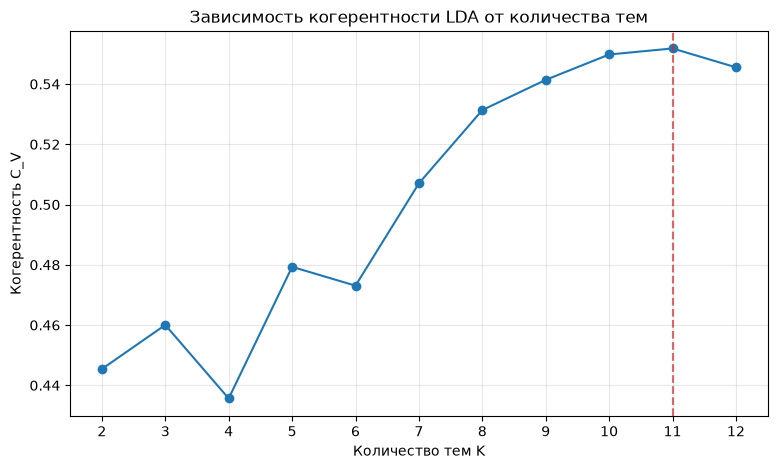

Максимум C_V: {'K': 11, 'C_V': 0.5518186891703042}


,K,C_V
8,10,0.549809
9,11,0.551819
10,12,0.545550


In [20]:
LDA_PASSES = 5
LDA_ITERATIONS = 100
LDA_CHUNKSIZE = 2000
lda_models = {}
coherence_rows = []

for topic_count in range(2, 13):
    lda_model = LdaModel(
        corpus=lda_corpus,
        id2word=lda_dictionary,
        num_topics=topic_count,
        random_state=RANDOM_STATE,
        chunksize=LDA_CHUNKSIZE,
        passes=LDA_PASSES,
        iterations=LDA_ITERATIONS,
        alpha="auto",
        eta="auto",
        eval_every=None,
    )
    coherence = CoherenceModel(
        model=lda_model,
        texts=lda_texts,
        dictionary=lda_dictionary,
        coherence="c_v",
        processes=1,
    ).get_coherence()
    lda_models[topic_count] = lda_model
    coherence_rows.append((topic_count, coherence))

coherence_df = pd.DataFrame(coherence_rows, columns=["K", "C_V"])
if not coherence_df["C_V"].map(math.isfinite).all():
    raise ValueError("Получено нечисловое значение когерентности.")
best_topic_count = int(
    coherence_df.sort_values(["C_V", "K"], ascending=[False, True]).iloc[0]["K"]
)
best_coherence = float(
    coherence_df.loc[coherence_df["K"] == best_topic_count, "C_V"].iloc[0]
)
best_lda_model = lda_models[best_topic_count]

display(coherence_df)
plt.figure(figsize=(9, 5))
plt.plot(coherence_df["K"], coherence_df["C_V"], marker="o")
plt.axvline(best_topic_count, color="tab:red", linestyle="--", alpha=0.7)
plt.xticks(range(2, 13))
plt.xlabel("Количество тем K")
plt.ylabel("Когерентность C_V")
plt.title("Зависимость когерентности LDA от количества тем")
plt.grid(alpha=0.3)
plt.show()

print("Максимум C_V:", {"K": best_topic_count, "C_V": best_coherence})
display(
    coherence_df[
        coherence_df["K"].between(best_topic_count - 1, best_topic_count + 1)
    ]
)


### Выбор оптимального количества тем

Максимальная когерентность в проверенном диапазоне достигнута при `K = 11`: $C_V = 0{,}5518$. Это немного выше значений при соседних `K = 10` (`0,5498`) и `K = 12` (`0,5456`). Топ-слова модели образуют интерпретируемые группы по выборам, экономике, праву, международной политике, здоровью и ресурсам, поэтому для дальнейшей интерпретации выбрано `K = 11`. Разница с `K = 10` невелика, но по формальному критерию максимума $C_V$ модель с 11 темами является оптимальной среди проверенных значений `2..12`.

# 7. Интерпретация тем

Для автоматически выбранной модели выводим ровно топ-10 слов с весами по каждой теме. Названия тем будут присвоены вручную только после получения результатов.

In [21]:
topic_rows = []
for topic_id, weighted_words in best_lda_model.show_topics(
    num_topics=best_topic_count,
    num_words=10,
    formatted=False,
):
    for rank, (word, weight) in enumerate(weighted_words, start=1):
        topic_rows.append((topic_id + 1, rank, word, weight))

topics_df = pd.DataFrame(
    topic_rows,
    columns=["Тема", "Ранг", "Слово", "Вес"],
)
assert topics_df["Тема"].nunique() == best_topic_count
assert topics_df.groupby("Тема").size().eq(10).all()
display(topics_df)

for topic_id in range(1, best_topic_count + 1):
    topic_words = topics_df.loc[
        topics_df["Тема"] == topic_id, "Слово"
    ].tolist()
    print(f"Тема {topic_id}: {', '.join(topic_words)}")


,Тема,Ранг,Слово,Вес
0,1,1,people,0.012595
1,1,2,like,0.010102
2,1,3,just,0.009685
3,1,4,time,0.006302
4,1,5,know,0.005476
...,...,...,...,...
105,11,6,justice,0.007652
106,11,7,case,0.007211
107,11,8,states,0.006992
108,11,9,gun,0.005996


Тема 1: people, like, just, time, know, don, right, way, going, world
Тема 2: obama, president, house, trump, congress, republicans, senate, republican, administration, white
Тема 3: syria, war, military, isis, syrian, forces, state, government, iraq, attack
Тема 4: police, ukrainian, israel, que, city, government, people, officers, protesters, los
Тема 5: russia, russian, ukraine, war, states, united, nato, world, nuclear, president
Тема 6: trump, clinton, hillary, election, campaign, party, donald, vote, republican, presidential
Тема 7: percent, economic, government, economy, market, tax, trade, year, jobs, american
Тема 8: trump, clinton, news, media, hillary, fbi, president, investigation, emails, email
Тема 9: money, million, company, new, foundation, soros, business, government, financial, state
Тема 10: water, health, food, new, use, energy, pipeline, change, study, people
Тема 11: law, court, state, rights, federal, justice, case, states, gun, legal


### Названия и интерпретация тем

| Тема | Название | Краткое описание |
|---:|---|---|
| 1 | Разговорная общественная риторика | Общие оценочные и разговорные слова о людях, времени и действиях. |
| 2 | Федеральная политика США | Президент, Белый дом, Конгресс, Сенат, республиканцы и работа администрации. |
| 3 | Военные конфликты и Ближний Восток | Сирия, ISIS, Ирак, вооружённые силы, атаки и действия правительств. |
| 4 | Полиция, протесты и международные события | Полиция, городские события, протестующие, Украина и Израиль; тема объединяет несколько слабо связанных сюжетов. |
| 5 | Россия и международная безопасность | Россия, Украина, США, NATO, война и ядерная политика. |
| 6 | Президентские выборы 2016 года | Трамп, Клинтон, партии, голосование и избирательная кампания. |
| 7 | Экономика, налоги и занятость | Экономические показатели, рынки, налоги, торговля и рабочие места. |
| 8 | Расследования вокруг выборов | Трамп, Клинтон, FBI, электронная почта, медиа и предвыборные расследования. |
| 9 | Бизнес, финансы и фонды | Деньги, компании, бизнес, финансовые вопросы, фонды и крупные суммы. |
| 10 | Здоровье, экология и ресурсы | Здоровье, вода, питание, энергия, трубопроводы, климатические изменения и исследования. |
| 11 | Право, гражданские права и оружие | Суды, федеральное и региональное право, юстиция, права и оружие. |

Темы в целом различимы и предметно интерпретируемы. Наиболее заметны пересечения тем 6 и 8 по выборам и фигурам Трампа/Клинтон, тем 3 и 5 по военным конфликтам и международной политике, а также тем 7 и 9 по экономической лексике. Тема 1 является фоновой и хуже остальных привязана к предметной области, а тема 4 смешивает полицейские, протестные и международные сюжеты. Это показывает, что максимум $C_V$ не устраняет полностью тематические пересечения и неоднородные компоненты.